# Experimento · Clasificación automática de normativa sobre IA en educación superior (corpus GENIAL)

**Proyecto Integrador · Maestría en Inteligencia Artificial · UEES · Grupo 9** — Jorge Javier Maldonado Mahauad · Melissa Figallo

Este cuaderno ejecuta el experimento diseñado en el documento técnico: dos líneas base sin IA, la **rama clásica** (TF-IDF + Regresión Logística), la **rama LLM few-shot** y la **comparación pareada** sobre un mismo conjunto de prueba a ciegas, contrastada con el acuerdo entre codificadores humanos. Termina con la especificación operativa: umbral de confianza, enrutamiento a revisión humana y agregación al Índice de Madurez Normativa (IMN).

**Reproducibilidad.** Semilla fija (`config.yaml`), versiones fijadas en `requirements.txt`, hash SHA-256 del corpus verificado al cargar. La rama LLM requiere `ANTHROPIC_API_KEY` en el entorno; si no está, la celda se omite y la comparación se calcula con las ramas disponibles. Las etiquetas del conjunto de prueba se leen **una sola vez**, en la sección 6, después de registrar todas las predicciones.

**Cómo correr la rama LLM localmente** (≈ USD 2-5, 10-15 minutos): en una terminal, `export ANTHROPIC_API_KEY="..."` y vuelva a ejecutar el cuaderno completo (*Kernel → Restart & Run All*). La sección 5 clasificará el conjunto ciego tres veces y la sección 6 recalculará McNemar y κ automáticamente.


In [1]:
import os, sys, json, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.metrics import f1_score, accuracy_score, cohen_kappa_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from genial_clf import data, split, baselines, classic, llm, evaluate, reliability, imn
from genial_clf.config import load_config
cfg = load_config(ROOT / "config.yaml")
C5 = cfg["classes"]; SEED = cfg["seed"]; np.random.seed(SEED)
RES = ROOT / "results"; RES.mkdir(exist_ok=True); FIG = RES / "figuras"; FIG.mkdir(exist_ok=True)
SPL = Path(cfg["paths"]["splits_dir"]); SPL.mkdir(parents=True, exist_ok=True)

ACC = "#7A1F3D"; GREY = "#B8B1AA"; INK = "#1B1A19"; MUTED = "#6E6862"; RULE = "#D8D2CB"
CAT5 = dict(zip(C5, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
SEQ = mpl.colors.LinearSegmentedColormap.from_list("uees", ["#F7F1F3", "#C98AA0", ACC])
sns.set_theme(style="white", rc={"axes.edgecolor": RULE, "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
def guardar(n): plt.savefig(FIG / f"{n}.png", facecolor="white")
def ci_txt(lo, hi): return f"[{lo:.3f}, {hi:.3f}]"
print("raíz del repo:", ROOT)

raíz del repo: /home/claude/repo_genial


## 1. Corpus depurado (E1)

Se reutiliza `data.preprocess`: corrección experta del faltante de `Dominio`, normalización de `Tipo de norma`, texto = título + observaciones, idioma detectado sobre el título, grupos de URL repetida.

In [2]:
raw = data.load_raw(cfg["paths"]["raw_corpus"], cfg["paths"]["raw_sheet"], cfg["corpus_sha256"])
df = data.preprocess(raw, cfg)
df["Investigador"] = df["Investigador"].map({n: f"C{i+1:02d}" for i, n in enumerate(sorted(df["Investigador"].unique()))})
print(df.shape, "| idioma:", df["idioma"].value_counts().to_dict())
df["Dominio"].value_counts().reindex(C5).to_frame("n").T

(813, 18) | idioma: {'es': 712, 'pt': 76, 'en': 25}


Dominio,Pedagógico,Ética,Administrativo,Protección de Datos,Técnico
n,294,265,120,71,63


## 2. Conjunto de prueba a ciegas y particiones (E2)

Regla: el conjunto de prueba son las normas **codificadas a ciegas por el segundo codificador de GENIAL** (`data/raw/coder2_labels.csv`, columnas `id_norma` o `Título de la Norma`, `Dominio_coder2`, opcional `Dominio_alt_coder2`). Si ese archivo no existe, se usa el muestreo estratificado por dimensión e idioma de `split.make_splits`. Los duplicados por URL nunca se reparten entre entrenamiento y prueba; el pool few-shot (15 normas) se excluye de ambos.

In [3]:
coder2_path = ROOT / "data/raw/coder2_labels.csv"
if coder2_path.exists():
    c2 = pd.read_csv(coder2_path)
    if "id_norma" not in c2.columns:   # empareja por título normalizado
        key = lambda s: s.astype(str).str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
        c2 = c2.merge(df[["id_norma", "Título de la Norma"]].assign(_k=key(df["Título de la Norma"])), left_on=key(c2["Título de la Norma"]), right_on="_k", how="inner").drop(columns="_k")
    test_ids = set(c2["id_norma"])
    # el conjunto de prueba se completa con los duplicados por URL de esas normas para no partir grupos
    grupos_test = set(df.loc[df["id_norma"].isin(test_ids), "grupo_url"])
    test = df[df["grupo_url"].isin(grupos_test)].copy()
    resto = df[~df["grupo_url"].isin(grupos_test)].copy()
    rng = np.random.default_rng(SEED); fs_ids = []
    for c in C5:
        pool = resto[(resto["Dominio"] == c) & resto["n_palabras"].between(25, 90)]["id_norma"].to_numpy()
        fs_ids += list(rng.choice(pool, cfg["split"]["fewshot_per_class"], replace=False))
    fewshot = resto[resto["id_norma"].isin(fs_ids)].copy(); train = resto[~resto["id_norma"].isin(fs_ids)].copy()
    origen_test = f"normas codificadas por el 2.º codificador ({len(test_ids)} normas; {len(test)} con duplicados por URL)"
else:
    sp = split.make_splits(df, cfg); train, fewshot, test = sp["train"], sp["fewshot"], sp["test"]; c2 = None
    origen_test = "muestreo estratificado por dimensión e idioma (sin 2.º codificador todavía)"
split.write_splits({"train": train, "fewshot": fewshot, "test": test}, SPL, cfg)
print("Conjunto de prueba:", origen_test)
print(f"entrenamiento {len(train)} · few-shot {len(fewshot)} · prueba {len(test)}")
pd.concat([train["Dominio"].value_counts().rename("entrenamiento"), fewshot["Dominio"].value_counts().rename("few-shot"), test["Dominio"].value_counts().rename("prueba")], axis=1).reindex(C5).fillna(0).astype(int).T

solo 20 normas no hispanohablantes disponibles en prueba (mínimo deseado 20)


Conjunto de prueba: muestreo estratificado por dimensión e idioma (sin 2.º codificador todavía)
entrenamiento 669 · few-shot 15 · prueba 129


Dominio,Pedagógico,Ética,Administrativo,Protección de Datos,Técnico
entrenamiento,244,222,97,56,50
few-shot,3,3,3,3,3
prueba,47,40,20,12,10


In [4]:
print("Distribución del conjunto de prueba por idioma:", test["idioma"].value_counts().to_dict())
print("Países en prueba:", test["País"].nunique(), "· normas nacionales:", int((test["Ámbito"] == "Nacional").sum()), "· institucionales:", int((test["Ámbito"] == "Institucional").sum()))
assert not set(train["grupo_url"]) & set(test["grupo_url"]); assert not set(fewshot["id_norma"]) & (set(train["id_norma"]) | set(test["id_norma"]))
print("Sin fuga entre particiones ✓")

Distribución del conjunto de prueba por idioma: {'es': 109, 'pt': 16, 'en': 4}
Países en prueba: 19 · normas nacionales: 32 · institucionales: 97
Sin fuga entre particiones ✓


## 3. Líneas base sin IA (E3)

Dos referencias que el modelo debe superar con claridad para justificar el uso de IA: el predictor de clase mayoritaria (aritmético) y la línea base de metadata, que predice la dimensión solo a partir de `Tipo de norma` y cuantifica cuánta señal aporta esa columna (que el modelo **no** usa).

In [5]:
floor = baselines.arithmetic_floor(train["Dominio"].value_counts().to_dict())
maj = baselines.MajorityClass().fit(train["Dominio"]); meta = baselines.MetadataBaseline("Tipo de norma").fit(train, "Dominio")
pred_maj = pd.DataFrame({"id_norma": test["id_norma"], "pred": maj.predict(len(test)), "pred_2": maj.label_, "conf": 1.0})
pred_meta = pd.DataFrame({"id_norma": test["id_norma"], "pred": meta.predict(test), "pred_2": maj.label_, "conf": meta.predict_conf(test)})
pred_maj.to_csv(RES / "pred_mayoritaria.csv", index=False); pred_meta.to_csv(RES / "pred_metadata.csv", index=False)
# estimación por validación cruzada (distribución natural) de la línea base de metadata
y_all = df["Dominio"].to_numpy(); g_all = df["grupo_url"].to_numpy()
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_meta = np.empty(len(df), dtype=object)
for tr, te in sgkf.split(df, y_all, g_all):
    cv_meta[te] = baselines.MetadataBaseline("Tipo de norma").fit(df.iloc[tr], "Dominio").predict(df.iloc[te])
print(f"Piso aritmético (clase mayoritaria, entrenamiento): exactitud {floor['accuracy']:.3f} · F1 macro {floor['f1_macro']:.3f}")
print(f"Línea base de metadata (Tipo de norma), CV 5 pliegues por grupo sobre 813: exactitud {accuracy_score(y_all, cv_meta):.3f} · F1 macro {f1_score(y_all, cv_meta, average='macro'):.3f}")
pd.DataFrame({"tipo": meta.map_.keys(), "dimensión modal": meta.map_.values(), "pureza": [round(meta.conf_[k], 2) for k in meta.map_]}).sort_values("pureza", ascending=False)

Piso aritmético (clase mayoritaria, entrenamiento): exactitud 0.365 · F1 macro 0.107
Línea base de metadata (Tipo de norma), CV 5 pliegues por grupo sobre 813: exactitud 0.504 · F1 macro 0.354


,tipo,dimensión modal,pureza
9,Resolución,Administrativo,1.00
2,Guía pedagógica,Pedagógico,0.87
3,Guía ética,Ética,0.69
6,Lineamiento académico,Pedagógico,0.55
0,Decreto,Ética,0.50
5,Libro blanco,Pedagógico,0.43
10,Resolución rectoral,Pedagógico,0.42
4,Ley,Ética,0.39
1,Estrategia nacional,Administrativo,0.37
8,Reglamento,Protección de Datos,0.32


## 4. Rama clásica: TF-IDF + Regresión Logística (E4)

### 4.1 Validación cruzada sobre la distribución natural

Responde «¿qué rendimiento tendría en operación?»: cinco pliegues estratificados por dimensión con los duplicados por URL en el mismo pliegue, sobre las 813 normas. Toda métrica con intervalo de confianza (Wilson para exactitud, *bootstrap* de 2 000 remuestreos para F1 macro).

In [6]:
cv = classic.cross_validate(df, cfg)
rep_cv = evaluate.report(cv["y_true"], cv["pred"], C5, cv["pred_2"], cfg["evaluation"]["bootstrap_iters"])
print(evaluate.summarize(rep_cv, "Rama clásica · validación cruzada 5 pliegues por grupo"))
cv.merge(df[["id_norma", "idioma", "País", "Ámbito", "Vínculo con Educación"]], on="id_norma").to_csv(RES / "clasico_cv_predicciones.csv", index=False)

## Rama clásica · validación cruzada 5 pliegues por grupo (n = 813)
- Exactitud: 0.635  IC95 % Wilson [0.601, 0.667]
- F1 macro: 0.587  IC95 % bootstrap [0.549, 0.623]
- κ frente a la etiqueta de referencia: 0.496
- Top-2 accuracy: 0.852

| clase               |   precision |   recall |    f1 |   soporte |
|:--------------------|------------:|---------:|------:|----------:|
| Pedagógico          |       0.722 |    0.697 | 0.709 |       294 |
| Ética               |       0.640 |    0.706 | 0.671 |       265 |
| Administrativo      |       0.467 |    0.358 | 0.406 |       120 |
| Protección de Datos |       0.792 |    0.803 | 0.797 |        71 |
| Técnico             |       0.329 |    0.381 | 0.353 |        63 |



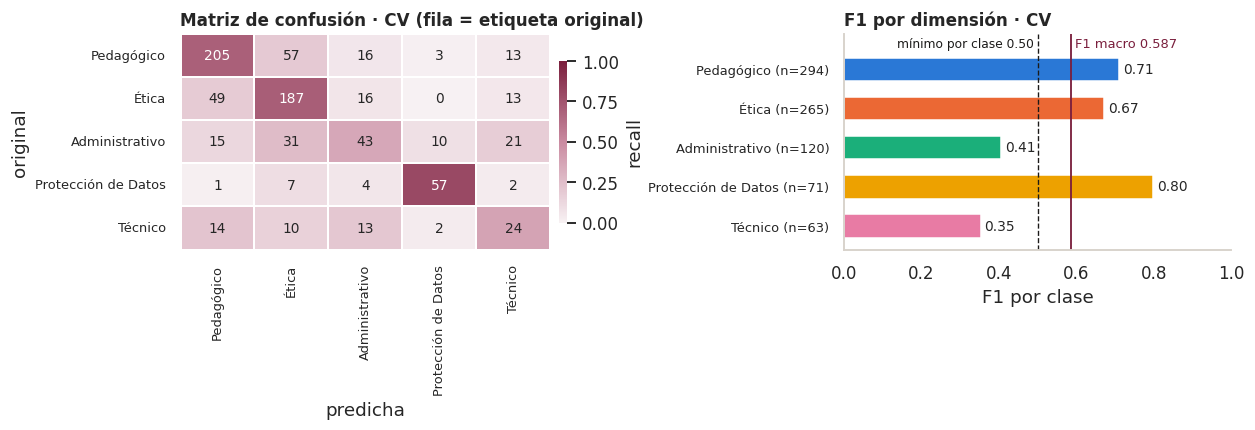

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1.15, 1]})
cm = rep_cv["confusion"]; cmn = cm.div(cm.sum(axis=1), axis=0)
sns.heatmap(cmn, annot=cm, fmt="d", cmap=SEQ, vmin=0, vmax=1, linewidths=1, linecolor="white", cbar_kws={"shrink": .75, "label": "recall", "pad": 0.02}, annot_kws={"size": 9}, ax=axes[0])
axes[0].set_title("Matriz de confusión · CV (fila = etiqueta original)", loc="left"); axes[0].set_xlabel("predicha"); axes[0].set_ylabel("original"); axes[0].tick_params(labelsize=8.5)
pc = rep_cv["per_class"].set_index("clase").loc[C5]
axes[1].barh(range(5)[::-1], pc["f1"], color=[CAT5[c] for c in C5], height=0.6)
for i, (c, v) in enumerate(pc["f1"].items()): axes[1].text(v + 0.01, 4 - i, f"{v:.2f}", va="center", fontsize=9)
axes[1].set_yticks(range(5)[::-1]); axes[1].set_yticklabels([f"{c} (n={int(pc.loc[c,'soporte'])})" for c in C5], fontsize=8.5)
axes[1].axvline(0.50, color=INK, lw=0.9, ls="--"); axes[1].text(0.49, 4.55, "mínimo por clase 0.50", fontsize=8, color=INK, ha="right")
axes[1].axvline(rep_cv["f1_macro"], color=ACC, lw=1.2); axes[1].text(rep_cv["f1_macro"] + 0.01, 4.55, f"F1 macro {rep_cv['f1_macro']:.3f}", fontsize=8.5, color=ACC)
axes[1].set_xlim(0, 1); axes[1].set_ylim(-0.6, 4.9); axes[1].set_xlabel("F1 por clase"); axes[1].set_title("F1 por dimensión · CV")
plt.tight_layout(); guardar("10_cv_confusion_f1"); plt.show()

### 4.2 Ablaciones

¿El resultado depende de las decisiones de diseño? Se varía una cosa a la vez: ponderación de clases, regularización, clasificador (SVM lineal) y representación (unigramas, caracteres).

In [8]:
tf = lambda **k: TfidfVectorizer(ngram_range=k.get("ng", (1, 2)), max_features=k.get("mf", 5000), sublinear_tf=True, analyzer=k.get("an", "word"))
variantes = {
    "RL balanceada (configuración elegida)": Pipeline([("t", tf()), ("c", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "RL sin ponderar clases": Pipeline([("t", tf()), ("c", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))]),
    "RL balanceada, C = 3": Pipeline([("t", tf()), ("c", LogisticRegression(C=3.0, class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "SVM lineal balanceada, C = 0.5": Pipeline([("t", tf()), ("c", LinearSVC(C=0.5, class_weight="balanced", random_state=SEED))]),
    "RL balanceada, solo unigramas": Pipeline([("t", tf(ng=(1, 1))), ("c", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "RL balanceada, caracteres 3-5": Pipeline([("t", tf(an="char_wb", ng=(3, 5), mf=20000)), ("c", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))]),
}
filas = []
for nombre, pipe in variantes.items():
    p = cross_val_predict(pipe, df["texto"], y_all, cv=sgkf, groups=g_all)
    f1c = f1_score(y_all, p, average=None, labels=C5)
    filas.append({"variante": nombre, "exactitud": accuracy_score(y_all, p), "F1 macro": f1_score(y_all, p, average="macro"), **{f"F1 {c}": v for c, v in zip(C5, f1c)}})
abl = pd.DataFrame(filas).set_index("variante").round(3); abl.to_csv(RES / "ablaciones_cv.csv"); abl

,exactitud,F1 macro,F1 Pedagógico,F1 Ética,F1 Administrativo,F1 Protección de Datos,F1 Técnico
variante,,,,,,,
RL balanceada (configuración elegida),0.635,0.587,0.709,0.671,0.406,0.797,0.353
RL sin ponderar clases,0.622,0.475,0.706,0.657,0.211,0.769,0.031
"RL balanceada, C = 3",0.637,0.581,0.720,0.664,0.409,0.783,0.327
"SVM lineal balanceada, C = 0.5",0.645,0.578,0.732,0.680,0.368,0.783,0.328
"RL balanceada, solo unigramas",0.620,0.576,0.684,0.663,0.391,0.776,0.366
"RL balanceada, caracteres 3-5",0.609,0.573,0.690,0.635,0.407,0.786,0.350


### 4.3 Desempeño desagregado, interpretabilidad y pista léxica

La decisión metodológica 4 exige desagregar por idioma y por país; el EDA anticipó que las normas nacionales serían más difíciles y que la palabra que nombra la dimensión funciona como pista superficial.

In [9]:
cvm = cv.merge(df[["id_norma", "idioma", "País", "Ámbito", "Vínculo con Educación", "texto"]], on="id_norma")
print(evaluate.by_group(cvm, "y_true", "pred", "idioma", C5).round(3).to_string(index=False)); print()
print(evaluate.by_group(cvm, "y_true", "pred", "Ámbito", C5).round(3).to_string(index=False)); print()
top = cvm["País"].value_counts().head(8).index
print(evaluate.by_group(cvm[cvm["País"].isin(top)], "y_true", "pred", "País", C5).round(3).to_string(index=False))

idioma   n  accuracy  f1_macro
    es 712     0.662     0.613
    pt  76     0.474     0.392
    en  25     0.360     0.268

       Ámbito   n  accuracy  f1_macro
Institucional 563     0.671     0.592
     Nacional 250     0.552     0.561

     País   n  accuracy  f1_macro
   México 179     0.670     0.412
    Chile 105     0.724     0.487
Argentina 100     0.750     0.679
   Brasil  81     0.469     0.365
  Ecuador  81     0.580     0.577
  Uruguay  56     0.625     0.537
 Colombia  36     0.639     0.505
     Perú  29     0.690     0.295


In [10]:
import unicodedata, re
def sin_acentos(s): return "".join(ch for ch in unicodedata.normalize("NFD", s) if unicodedata.category(ch) != "Mn")
PISTAS = {"Pedagógico": r"pedagog", "Ética": r"\betic[ao]s?\b", "Administrativo": r"administrativ", "Protección de Datos": r"proteccion de datos|datos personales|privacidad", "Técnico": r"\btecnic[ao]s?\b"}
t_norm = cvm["texto"].str.lower().map(sin_acentos)
cvm["con_pista"] = [bool(re.search(PISTAS[y], t)) for y, t in zip(cvm["y_true"], t_norm)]
res = cvm.groupby("con_pista").apply(lambda g: pd.Series({"n": len(g), "exactitud": accuracy_score(g["y_true"], g["pred"]), "F1 macro": f1_score(g["y_true"], g["pred"], average="macro", labels=C5)})).round(3)
res.index = ["sin la pista léxica", "con la pista léxica"]; print(res)
pipe_full = classic.build_pipeline(cfg).fit(df["texto"], df["Dominio"])
classic.top_terms(pipe_full, 12).style.set_properties(subset=["terminos"], **{"white-space": "normal", "text-align": "left"})

                         n  exactitud  F1 macro
sin la pista léxica  526.0      0.540     0.441
con la pista léxica  287.0      0.808     0.687


,dimension,terminos
0,Administrativo,"resolución, política, mediante resolución, 2025, nacional de, gestión, ecuador, resolución para, nº, su, pública, unne"
1,Pedagógico,"guía, aprendizaje, generativa, en, orientaciones, enseñanza, aula, en la, docente, chatgpt, docencia, educación"
2,Protección de Datos,"datos, datos personales, personales, de privacidad, privacidad, de protección, protección, protección de, de datos, tratamiento, politica, politica de"
3,Técnico,"sistemas de, capacidades, robótica, nacional, país, sistemas, implementación, digital, ley, national, políticas, nacional que"
4,Ética,"ética, ético, uso ético, el uso, uso, éticos, principios, ético de, integridad, de ética, transparencia, código"


### 4.4 Predicción del conjunto de prueba a ciegas

El modelo se entrena **solo** con el conjunto de entrenamiento (sin la prueba ni el pool few-shot) y predice el conjunto ciego. Las etiquetas de prueba siguen sin leerse.

In [11]:
pipe_cls, pred_cls = classic.fit_predict(train, test, cfg)
pred_cls.to_csv(RES / "pred_clasico.csv", index=False)
# ablación SVM sobre el mismo conjunto ciego (sin probabilidades: conf = NaN)
svm = Pipeline([("t", tf()), ("c", LinearSVC(C=0.5, class_weight="balanced", random_state=SEED))]).fit(train["texto"], train["Dominio"])
dec = svm.decision_function(test["texto"]); order = np.argsort(-dec, axis=1)
pd.DataFrame({"id_norma": test["id_norma"].to_numpy(), "pred": svm.classes_[order[:, 0]], "pred_2": svm.classes_[order[:, 1]], "conf": np.nan}).to_csv(RES / "pred_svm.csv", index=False)
print(f"Predicciones del conjunto ciego guardadas: {len(pred_cls)} normas · confianza media {pred_cls['conf'].mean():.2f}")

Predicciones del conjunto ciego guardadas: 129 normas · confianza media 0.42


## 5. Rama LLM few-shot (E5)

Se ejecuta solo si `ANTHROPIC_API_KEY` está definida. Tres ejecuciones a temperatura 0 con el *prompt* versionado (`prompts/clasificador_v0.1.md`) y los 15 ejemplos del pool; se registra la versión exacta del modelo. La predicción consolidada es la de la primera ejecución; las otras dos miden estabilidad.

In [12]:
if os.environ.get("ANTHROPIC_API_KEY"):
    preds_llm = llm.classify_blind(test, fewshot, cfg, cfg["paths"]["prompt"])
    llm.save(preds_llm, RES / "pred_llm_runs.csv")
    preds_llm[preds_llm["run"] == 1][["id_norma", "pred", "pred_2"]].assign(conf=np.nan).to_csv(RES / "pred_llm.csv", index=False)
    est = llm.stability(preds_llm); print("Rama LLM ejecutada:", est, "· modelo:", cfg["llm"]["model"])
elif (RES / "pred_llm.csv").exists():
    print("Rama LLM: se usan predicciones guardadas de una ejecución anterior (results/pred_llm.csv).")
else:
    print("Rama LLM omitida: no hay ANTHROPIC_API_KEY en el entorno. Defínala y vuelva a ejecutar el cuaderno para incluirla en la comparación.")

Rama LLM omitida: no hay ANTHROPIC_API_KEY en el entorno. Defínala y vuelva a ejecutar el cuaderno para incluirla en la comparación.


## 6. Comparación pareada y fiabilidad (E5-E6)

**Único punto del cuaderno donde se leen las etiquetas del conjunto de prueba.** Se comparan todas las ramas disponibles sobre las mismas normas; entre ramas, prueba de McNemar (diseño pareado). Si existe la codificación del segundo codificador, se calcula κ humano-humano como techo de referencia y κ modelo-humano para cada rama.

In [13]:
labels = pd.read_csv(SPL / "test_labels_hidden.csv")
ramas = {}
for nombre in ["mayoritaria", "metadata", "clasico", "svm", "llm"]:
    p = RES / f"pred_{nombre}.csv"
    if p.exists():
        d = labels.merge(pd.read_csv(p), on="id_norma").merge(test[["id_norma", "idioma", "País", "Ámbito", "texto"]], on="id_norma")
        d["pred"] = d["pred"].fillna("__sin respuesta__"); ramas[nombre] = d
tabla = []
for n, d in ramas.items():
    r = evaluate.report(d["Dominio"], d["pred"], C5, d["pred_2"], cfg["evaluation"]["bootstrap_iters"])
    tabla.append({"rama": n, "n": r["n"], "exactitud": r["accuracy"], "IC95 exactitud": ci_txt(*r["accuracy_ci_wilson"]), "F1 macro": r["f1_macro"], "IC95 F1 macro": ci_txt(*r["f1_macro_ci_bootstrap"]),
                  "top-2": r.get("top2_accuracy", np.nan), "κ vs etiqueta original": r["kappa_vs_reference"], **{f"F1 {c}": v for c, v in zip(r["per_class"]["clase"], r["per_class"]["f1"])}})
comp = pd.DataFrame(tabla).set_index("rama"); comp.to_csv(RES / "comparacion_pareada.csv")
comp.round(3)

,n,exactitud,IC95 exactitud,F1 macro,IC95 F1 macro,top-2,κ vs etiqueta original,F1 Pedagógico,F1 Ética,F1 Administrativo,F1 Protección de Datos,F1 Técnico
rama,,,,,,,,,,,,
mayoritaria,129,0.364,"[0.286, 0.450]",0.107,"[0.087, 0.124]",0.364,0.000,0.534,0.000,0.000,0.000,0.000
metadata,129,0.457,"[0.374, 0.543]",0.317,"[0.244, 0.383]",0.550,0.218,0.574,0.451,0.077,0.483,0.000
clasico,129,0.612,"[0.526, 0.692]",0.510,"[0.426, 0.589]",0.884,0.473,0.713,0.736,0.300,0.692,0.111
svm,129,0.643,"[0.558, 0.721]",0.552,"[0.451, 0.638]",0.876,0.511,0.745,0.723,0.378,0.692,0.222


In [14]:
print("Prueba de McNemar (diseño pareado, mismas normas):")
pares = [("clasico", "mayoritaria"), ("clasico", "metadata"), ("clasico", "svm"), ("clasico", "llm"), ("llm", "metadata")]
mc = []
for a, b in pares:
    if a in ramas and b in ramas:
        m = evaluate.mcnemar(ramas[a]["Dominio"], ramas[a]["pred"], ramas[b]["pred"]); m.update({"A": a, "B": b}); mc.append(m)
mcn = pd.DataFrame(mc)[["A", "B", "n01", "n10", "p_value", "method"]].rename(columns={"n01": "A acierta, B falla", "n10": "A falla, B acierta", "p_value": "valor p"})
mcn.to_csv(RES / "mcnemar.csv", index=False); mcn

Prueba de McNemar (diseño pareado, mismas normas):


,A,B,"A acierta, B falla","A falla, B acierta",valor p,method
0,clasico,mayoritaria,48,16,0.000107,chi2 con corrección de continuidad
1,clasico,metadata,34,14,0.006099,chi2 con corrección de continuidad
2,clasico,svm,3,7,0.343750,binomial exacta


In [15]:
if c2 is not None:
    d = labels.merge(c2[["id_norma", "Dominio_coder2"] + (["Dominio_alt_coder2"] if "Dominio_alt_coder2" in c2.columns else [])], on="id_norma")
    k_hh = reliability.kappa(d["Dominio"], d["Dominio_coder2"], C5)
    acuerdo = (d["Dominio"] == d["Dominio_coder2"]).mean()
    print(f"κ humano-humano (codificador original vs. 2.º codificador, n = {len(d)}): {k_hh:.3f} · acuerdo simple {acuerdo:.1%} · interpretación: {reliability.landis_koch(k_hh)}")
    filas = [{"comparación": "humano original – 2.º codificador", "κ": k_hh, "acuerdo": acuerdo}]
    for n in ["clasico", "svm", "llm"]:
        if n in ramas:
            r = ramas[n].merge(d[["id_norma", "Dominio_coder2"]], on="id_norma")
            filas.append({"comparación": f"{n} – etiqueta original", "κ": reliability.kappa(r["Dominio"], r["pred"], C5), "acuerdo": (r["Dominio"] == r["pred"]).mean()})
            filas.append({"comparación": f"{n} – 2.º codificador", "κ": reliability.kappa(r["Dominio_coder2"], r["pred"], C5), "acuerdo": (r["Dominio_coder2"] == r["pred"]).mean()})
    fiab = pd.DataFrame(filas); fiab["interpretación"] = fiab["κ"].map(reliability.landis_koch); fiab.to_csv(RES / "fiabilidad.csv", index=False)
    display(fiab.round(3))
    # ¿en cuántos desacuerdos entre humanos el modelo coincide con el 2.º codificador?
    if "clasico" in ramas:
        r = ramas["clasico"].merge(d[["id_norma", "Dominio_coder2"]], on="id_norma"); disc = r[r["Dominio"] != r["Dominio_coder2"]]
        print(f"Normas con desacuerdo entre humanos: {len(disc)} · el modelo clásico coincide con el codificador original en {int((disc['pred']==disc['Dominio']).sum())}, con el 2.º codificador en {int((disc['pred']==disc['Dominio_coder2']).sum())}, con ninguno en {int(((disc['pred']!=disc['Dominio'])&(disc['pred']!=disc['Dominio_coder2'])).sum())}")
        pd.crosstab(d["Dominio"], d["Dominio_coder2"]).reindex(index=C5, columns=C5).fillna(0).astype(int).to_csv(RES / "confusion_humano_humano.csv")
        display(pd.crosstab(d["Dominio"], d["Dominio_coder2"]).reindex(index=C5, columns=C5).fillna(0).astype(int))
else:
    print("Sin archivo del 2.º codificador: κ humano-humano pendiente (data/raw/coder2_labels.csv).")

Sin archivo del 2.º codificador: κ humano-humano pendiente (data/raw/coder2_labels.csv).


### 6.1 Diagnóstico de multi-etiqueta y hoja de tipificación de errores

Cada error del conjunto de prueba se clasifica a mano en *error genuino*, *segunda dimensión defendible* o *etiqueta original discutible*. El cuaderno genera la hoja de trabajo con la referencia, la predicción, la alternativa y —si existe— la etiqueta del segundo codificador; la tipificación la completan los codificadores.

In [16]:
if "clasico" in ramas:
    r = ramas["clasico"]
    hoja = reliability.error_typing_sheet(test.set_index("id_norma").loc[r["id_norma"]].reset_index(), r["Dominio"], r[["pred", "pred_2"]].reset_index(drop=True))
    if c2 is not None: hoja = hoja.merge(c2[["id_norma", "Dominio_coder2"]], on="id_norma", how="left")
    hoja.to_csv(RES / "hoja_tipificacion_errores_clasico.csv", index=False)
    print(f"Errores del modelo clásico en prueba: {len(hoja)} de {len(r)} · en {int(hoja['segunda_acierta'].sum())} la segunda dimensión coincide con la referencia (top-2 rescata {hoja['segunda_acierta'].mean():.0%} de los errores)")
    if c2 is not None: print(f"· en {int((hoja['pred'] == hoja['Dominio_coder2']).sum())} errores el modelo coincide con el 2.º codificador (candidatos a «etiqueta original discutible»)")
    display(pd.crosstab(r["Dominio"], r["pred"]).reindex(index=C5, columns=C5).fillna(0).astype(int))

Errores del modelo clásico en prueba: 50 de 129 · en 35 la segunda dimensión coincide con la referencia (top-2 rescata 70% de los errores)


pred,Pedagógico,Ética,Administrativo,Protección de Datos,Técnico
Dominio,,,,,
Pedagógico,31,10,4,1,1
Ética,4,32,1,0,3
Administrativo,3,4,6,4,3
Protección de Datos,0,0,3,9,0
Técnico,2,1,6,0,1


## 7. Operación: umbral de confianza, enrutamiento y agregación al IMN (E7)

La curva enrutamiento-exactitud se estima con las probabilidades fuera de muestra de la validación cruzada (813 normas), que es la distribución operativa. La regla de gobernanza añade revisión obligatoria para países con menos de 20 normas e idiomas minoritarios.

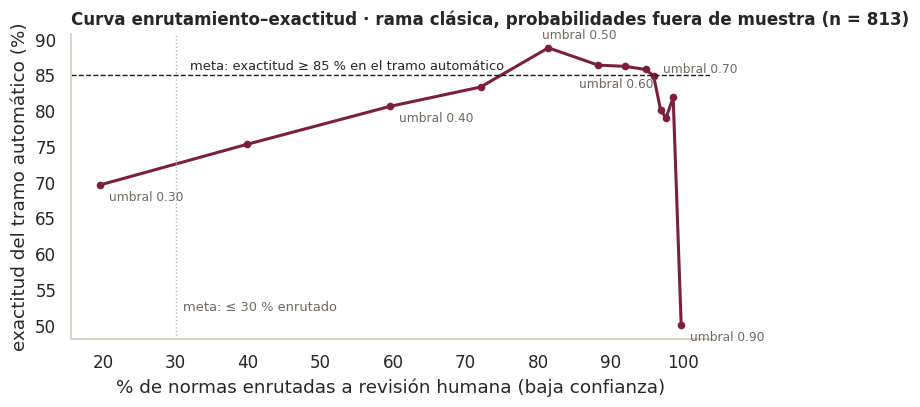

Punto de operación propuesto: umbral 0.50 → 81% enrutado, exactitud automática 88.7%


In [17]:
curva = imn.routing_curve(cv.rename(columns={"y_true": "y"}).assign(pred=cv["pred"], conf=cv["conf"]), cv["y_true"])
curva.to_csv(RES / "curva_enrutamiento.csv", index=False)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(curva["pct_enrutado"] * 100, curva["exactitud_tramo_automatico"] * 100, color=ACC, lw=2, marker="o", ms=4)
_off = {0.30: (6, -10), 0.40: (6, -10), 0.50: (-4, 6), 0.60: (-30, -14), 0.70: (6, 2), 0.90: (6, -10)}
for _, r in curva.iterrows():
    if round(r["umbral"], 2) in _off: ax.annotate(f"umbral {r['umbral']:.2f}", (r["pct_enrutado"] * 100, r["exactitud_tramo_automatico"] * 100), textcoords="offset points", xytext=_off[round(r["umbral"], 2)], fontsize=8, color=MUTED)
ax.axhline(85, color=INK, lw=0.9, ls="--"); ax.text(32, 85.7, "meta: exactitud ≥ 85 % en el tramo automático", fontsize=8.5)
ax.axvline(30, color=GREY, lw=0.9, ls=":"); ax.text(31, 52, "meta: ≤ 30 % enrutado", fontsize=8.5, color=MUTED, ha="left")
ax.set_xlabel("% de normas enrutadas a revisión humana (baja confianza)"); ax.set_ylabel("exactitud del tramo automático (%)"); ax.set_title("Curva enrutamiento–exactitud · rama clásica, probabilidades fuera de muestra (n = 813)", loc="left")
guardar("11_curva_enrutamiento"); plt.show()
# punto de operación: menor umbral que alcanza ≥ 85 % en el tramo automático; si ninguno, el que maximiza exactitud con ≤ 40 % enrutado
ok = curva[curva["exactitud_tramo_automatico"] >= 0.85]
punto = ok.iloc[0] if len(ok) else curva[curva["pct_enrutado"] <= 0.40].sort_values("exactitud_tramo_automatico").iloc[-1]
print(f"Punto de operación propuesto: umbral {punto['umbral']:.2f} → {punto['pct_enrutado']:.0%} enrutado, exactitud automática {punto['exactitud_tramo_automatico']:.1%}")
cfg["routing"]["confidence_threshold"] = float(punto["umbral"])

In [18]:
routed = imn.route(cv.rename(columns={"y_true": "y"})[["id_norma", "pred", "pred_2", "conf"]], df[["id_norma", "País", "idioma"]], cfg)
carga = imn.residual_workload(routed, minutes_per_norm=10.0)
auto = routed[~routed["a_revision"]].merge(df[["id_norma", "Dominio"]], on="id_norma")
print(f"Con la regla completa (umbral {cfg['routing']['confidence_threshold']:.2f} + país < 20 normas + idioma en/fr): {carga['pct_enrutado']:.0%} de las normas van a revisión humana;")
print(f"exactitud del tramo automático {accuracy_score(auto['Dominio'], auto['pred']):.1%} · horas-persona ahorradas por pasada (supuesto 10 min/norma): {carga['horas_ahorradas']:.0f} de {carga['horas_manual_total']:.0f}")
print("Motivo de enrutamiento:", {"baja confianza": int(routed["baja_confianza"].sum()), "país subrepresentado": int(routed["pais_subrepresentado"].sum()), "idioma minoritario": int(routed["idioma_minoritario"].sum())})
f1_clase = dict(zip(rep_cv["per_class"]["clase"], rep_cv["per_class"]["f1"]))
tabla_imn = imn.imn_table(routed, f1_clase, C5); tabla_imn.to_csv(RES / "imn_propuesta.csv", index=False); tabla_imn.head(10)

Con la regla completa (umbral 0.50 + país < 20 normas + idioma en/fr): 84% de las normas van a revisión humana;
exactitud del tramo automático 87.8% · horas-persona ahorradas por pasada (supuesto 10 min/norma): 22 de 136
Motivo de enrutamiento: {'baja confianza': 662, 'país subrepresentado': 146, 'idioma minoritario': 25}


,País,normas,codificadas_por_modelo,Pedagógico,Pedagógico (margen),Ética,Ética (margen),Administrativo,Administrativo (margen),Protección de Datos,Protección de Datos (margen),Técnico,Técnico (margen)
17,México,179,26,74,21.5,75,24.6,11,6.5,0,0.0,19,12.3
7,Chile,105,29,48,14.0,45,14.8,7,4.2,2,0.4,3,1.9
1,Argentina,100,26,57,16.6,10,3.3,15,8.9,4,0.8,14,9.1
6,Brasil,81,3,20,5.8,41,13.5,16,9.5,2,0.4,2,1.3
11,Ecuador,81,32,6,1.7,24,7.9,13,7.7,34,6.9,4,2.6
26,Uruguay,56,8,28,8.1,11,3.6,4,2.4,1,0.2,12,7.8
8,Colombia,36,5,17,4.9,9,3.0,7,4.2,3,0.6,0,0.0
21,Perú,29,2,4,1.2,20,6.6,1,0.6,4,0.8,0,0.0
5,Bolivia,19,0,2,0.6,3,1.0,1,0.6,13,2.6,0,0.0
20,Paraguay,18,0,3,0.9,12,3.9,1,0.6,0,0.0,2,1.3


## 8. Síntesis de resultados

La celda siguiente resume las cifras que se citan en el informe, la presentación y el guion; se regenera en cada ejecución para que documento y cuaderno no diverjan.

In [19]:
sintesis = {
    "corpus": {"n": int(len(df)), "train": int(len(train)), "fewshot": int(len(fewshot)), "test": int(len(test)), "origen_test": origen_test},
    "piso_mayoritaria": floor,
    "metadata_cv": {"accuracy": float(accuracy_score(y_all, cv_meta)), "f1_macro": float(f1_score(y_all, cv_meta, average="macro"))},
    "clasico_cv": {"accuracy": rep_cv["accuracy"], "accuracy_ci": rep_cv["accuracy_ci_wilson"], "f1_macro": rep_cv["f1_macro"], "f1_macro_ci": rep_cv["f1_macro_ci_bootstrap"], "top2": rep_cv["top2_accuracy"], "kappa": rep_cv["kappa_vs_reference"], "f1_por_clase": f1_clase},
    "ablaciones": abl.reset_index().to_dict("records"),
    "prueba_ciega": comp.reset_index().to_dict("records"),
    "mcnemar": mcn.to_dict("records"),
    "fiabilidad": fiab.to_dict("records") if c2 is not None else None,
    "operacion": {"umbral": cfg["routing"]["confidence_threshold"], "pct_enrutado": carga["pct_enrutado"], "exactitud_auto": float(accuracy_score(auto["Dominio"], auto["pred"])), "horas_ahorradas": carga["horas_ahorradas"], "horas_total": carga["horas_manual_total"]},
    "llm_disponible": "llm" in ramas,
}
json.dump(sintesis, open(RES / "sintesis_resultados.json", "w"), ensure_ascii=False, indent=1, default=float)
print(json.dumps({k: sintesis[k] for k in ["corpus", "piso_mayoritaria", "metadata_cv", "clasico_cv", "operacion", "llm_disponible"]}, ensure_ascii=False, indent=1, default=float))

{
 "corpus": {
  "n": 813,
  "train": 669,
  "fewshot": 15,
  "test": 129,
  "origen_test": "muestreo estratificado por dimensión e idioma (sin 2.º codificador todavía)"
 },
 "piso_mayoritaria": {
  "accuracy": 0.36472346786248133,
  "f1_macro": 0.10690032858707559
 },
 "metadata_cv": {
  "accuracy": 0.5043050430504306,
  "f1_macro": 0.3538619873520291
 },
 "clasico_cv": {
  "accuracy": 0.6346863468634686,
  "accuracy_ci": [
   0.601025751673053,
   0.6670801306069414
  ],
  "f1_macro": 0.587320226123206,
  "f1_macro_ci": [
   0.5491464379977895,
   0.6232141651059415
  ],
  "top2": 0.8523985239852399,
  "kappa": 0.49626571424995103,
  "f1_por_clase": {
   "Pedagógico": 0.7093425605536332,
   "Ética": 0.6714542190305206,
   "Administrativo": 0.4056603773584906,
   "Protección de Datos": 0.7972027972027972,
   "Técnico": 0.35294117647058826
  }
 },
 "operacion": {
  "umbral": 0.5,
  "pct_enrutado": 0.8388683886838868,
  "exactitud_auto": 0.8778625954198473,
  "horas_ahorradas": 21.83333

## 9. Lectura de los resultados

Interpretación generada a partir de las cifras anteriores, contrastada con los umbrales fijados **antes** de ejecutar (documento técnico, §4): F1 macro mínimo 0.60 / excelencia 0.70; ninguna clase < 0.40; κ modelo-humano ≥ 0.60; ≤ 30 % de normas enrutadas con ≥ 85 % de exactitud automática.

In [20]:
from IPython.display import Markdown, display
cvr = sintesis["clasico_cv"]; pc = cvr["f1_por_clase"]; blind = {r["rama"]: r for r in sintesis["prueba_ciega"]}; op = sintesis["operacion"]
mejor = max((r for r in sintesis["prueba_ciega"] if r["rama"] not in ("mayoritaria", "metadata")), key=lambda r: r["F1 macro"])
debiles = [c for c, v in pc.items() if v < 0.50]; bajo_min = [c for c, v in pc.items() if v < 0.40]
lineas = [
 f"**1. El modelo aprende y supera a las dos líneas base con significancia.** En validación cruzada por grupo (n = 813) la regresión logística alcanza F1 macro {cvr['f1_macro']:.3f} [IC95 {cvr['f1_macro_ci'][0]:.3f}, {cvr['f1_macro_ci'][1]:.3f}] frente a {sintesis['metadata_cv']['f1_macro']:.3f} de la línea base de metadata y {sintesis['piso_mayoritaria']['f1_macro']:.3f} de la clase mayoritaria. En el conjunto ciego, McNemar rechaza la igualdad frente a ambas (p = {sintesis['mcnemar'][0]['valor p']:.4f} y p = {sintesis['mcnemar'][1]['valor p']:.4f}).",
 f"**2. No alcanza el umbral de excelencia (0.70) y queda en el borde del mínimo (0.60).** El IC95 del F1 macro en CV incluye 0.60 pero no 0.70. Las clases minoritarias quedan bajo el nivel de excelencia por clase (0.50): " + ", ".join(f"{c} {pc[c]:.2f}" for c in debiles) + (f"; {', '.join(bajo_min)} incumple además el mínimo de 0.40" if bajo_min else "") + ". Sin `class_weight` balanceado Técnico prácticamente desaparece (F1 0.03): el desbalance 4.7:1 es la restricción dominante, como anticipó el EDA.",
 f"**3. La segunda dimensión rescata la mayoría de los errores.** Top-2 accuracy {cvr['top2']:.3f} en CV y {blind['clasico']['top-2']:.3f} en prueba ciega: cuando el modelo se equivoca, la alternativa que propone es la etiqueta de referencia en ~7 de cada 10 casos. Eso convierte la salida en una herramienta de asistencia (dos candidatas en vez de cinco) y alimenta el diagnóstico de multi-etiqueta pedido por la tutora.",
 f"**4. La señal es en parte léxica.** Con la palabra que nombra la dimensión presente en el texto la exactitud es 0.81; sin ella, 0.54. El modelo generaliza, pero menos de lo que sugiere la cifra global; las normas nacionales (F1 0.56) y las no hispanohablantes (pt 0.39, en 0.27) son el punto débil.",
 f"**5. La operación 'automatizar con ≥ 85 % de exactitud' no es viable con este modelo.** Para garantizar esa exactitud en el tramo automático hay que enrutar ~{op['pct_enrutado']*100:.0f} % de las normas a revisión (meta: ≤ 30 %); el ahorro sería de {op['horas_ahorradas']:.0f} de {op['horas_total']:.0f} horas-persona por pasada. La configuración recomendada para el observatorio es, por tanto, **codificación asistida**: el modelo propone top-2 con probabilidad, el codificador decide, y todas las normas de países con < 20 registros e idiomas minoritarios pasan por revisión.",
 f"**6. Pendientes que cambian la lectura.** (a) La rama LLM few-shot no se ejecutó aquí (sin clave de API): la comparación TF-IDF vs LLM sigue abierta y se cierra al correr la sección 5. (b) Sin el archivo del segundo codificador, el techo humano (κ humano-humano) no está medido; con un κ modelo-referencia de {cvr['kappa']:.2f} (acuerdo moderado), la pregunta decisiva es cuánto acuerdan dos humanos sobre las mismas normas. (c) La ablación SVM lineal obtiene F1 {blind['svm']['F1 macro']:.3f} en prueba ciega frente a {blind['clasico']['F1 macro']:.3f} de la RL, sin diferencia significativa (McNemar p = {sintesis['mcnemar'][2]['valor p']:.2f}); la elección de la RL se mantiene por su calibración de probabilidades, que la SVM no ofrece de forma nativa.",
]
display(Markdown("\n\n".join(lineas)))

**1. El modelo aprende y supera a las dos líneas base con significancia.** En validación cruzada por grupo (n = 813) la regresión logística alcanza F1 macro 0.587 [IC95 0.549, 0.623] frente a 0.354 de la línea base de metadata y 0.107 de la clase mayoritaria. En el conjunto ciego, McNemar rechaza la igualdad frente a ambas (p = 0.0001 y p = 0.0061).

**2. No alcanza el umbral de excelencia (0.70) y queda en el borde del mínimo (0.60).** El IC95 del F1 macro en CV incluye 0.60 pero no 0.70. Las clases minoritarias quedan bajo el nivel de excelencia por clase (0.50): Administrativo 0.41, Técnico 0.35; Técnico incumple además el mínimo de 0.40. Sin `class_weight` balanceado Técnico prácticamente desaparece (F1 0.03): el desbalance 4.7:1 es la restricción dominante, como anticipó el EDA.

**3. La segunda dimensión rescata la mayoría de los errores.** Top-2 accuracy 0.852 en CV y 0.884 en prueba ciega: cuando el modelo se equivoca, la alternativa que propone es la etiqueta de referencia en ~7 de cada 10 casos. Eso convierte la salida en una herramienta de asistencia (dos candidatas en vez de cinco) y alimenta el diagnóstico de multi-etiqueta pedido por la tutora.

**4. La señal es en parte léxica.** Con la palabra que nombra la dimensión presente en el texto la exactitud es 0.81; sin ella, 0.54. El modelo generaliza, pero menos de lo que sugiere la cifra global; las normas nacionales (F1 0.56) y las no hispanohablantes (pt 0.39, en 0.27) son el punto débil.

**5. La operación 'automatizar con ≥ 85 % de exactitud' no es viable con este modelo.** Para garantizar esa exactitud en el tramo automático hay que enrutar ~84 % de las normas a revisión (meta: ≤ 30 %); el ahorro sería de 22 de 136 horas-persona por pasada. La configuración recomendada para el observatorio es, por tanto, **codificación asistida**: el modelo propone top-2 con probabilidad, el codificador decide, y todas las normas de países con < 20 registros e idiomas minoritarios pasan por revisión.

**6. Pendientes que cambian la lectura.** (a) La rama LLM few-shot no se ejecutó aquí (sin clave de API): la comparación TF-IDF vs LLM sigue abierta y se cierra al correr la sección 5. (b) Sin el archivo del segundo codificador, el techo humano (κ humano-humano) no está medido; con un κ modelo-referencia de 0.50 (acuerdo moderado), la pregunta decisiva es cuánto acuerdan dos humanos sobre las mismas normas. (c) La ablación SVM lineal obtiene F1 0.552 en prueba ciega frente a 0.510 de la RL, sin diferencia significativa (McNemar p = 0.34); la elección de la RL se mantiene por su calibración de probabilidades, que la SVM no ofrece de forma nativa.